# Coral Genus Classification Pipeline v2
## Expanded genera + tiered auto-labeling + supervised classifier

**What changed from v1:**
1. **Expanded genera**: Added soft corals (Cladiella, Sinularia, Litophyton, Sarcophyton) + ensured Dipsastraea is properly represented
2. **Saves raw embeddings** alongside predictions (needed for supervised training)
3. **Tiered auto-labeling**: Auto-accepts high-confidence predictions for reliable genera, flags uncertain ones for expert review
4. **Expert review flow**: Generates a CSV + image grid for the domain expert to correct
5. **Supervised classifier**: After expert review, trains a LogisticRegression on BioCLIP-FT embeddings
6. **Re-classification**: Applies the trained classifier to all corals for final labels

**Two-phase workflow:**
- **Phase 1** (run first): Zero-shot classification → tiered auto-labeling → expert review CSV
- **Phase 2** (after expert review): Load corrections → train classifier → final labels

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install open_clip_torch torch torchvision pycocotools scikit-learn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 85.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.4 MB/s eta 0:00:00


## Configuration
All paths and parameters in one place. Same structure as v1.

In [3]:
import os
import torch
import cv2
import json
import numpy as np
import pandas as pd
from tqdm import tqdm
from PIL import Image
import open_clip
import pycocotools.mask as mask_util
import matplotlib.pyplot as plt
import random
import glob
import warnings
warnings.filterwarnings('ignore')

# ══════════════════════════════════════════════════════════════
# PHASE CONTROL — set to 1 for first run, 2 after expert review
# ══════════════════════════════════════════════════════════════
PHASE = 1   # 1 = zero-shot + generate expert review CSV
            # 2 = load expert corrections + train classifier

# ══════════════════════════════════════════════════════════════
# PATHS  (identical to v1)
# ══════════════════════════════════════════════════════════════
POINTS_PER_SIDE    = 32
IOU_THRESH         = 0.60
STABILITY_THRESH   = 0.55
MIN_MASK_REGION_AREA = 100

RUN_NAME = f"iou{int(IOU_THRESH*100)}_sta{int(STABILITY_THRESH*100)}_pts{int(POINTS_PER_SIDE)}"
print(f"Run name: {RUN_NAME}")

base_path        = '/content/drive/MyDrive/colab notebooks/CoralsMasking'
data_path        = os.path.join(base_path, 'data_all')
repo_path        = os.path.join(base_path, 'CoralSCOP')
checkpoints_path = os.path.join(repo_path, 'checkpoints')
results_root     = os.path.join(base_path, 'results_all')
run_dir          = os.path.join(results_root, RUN_NAME)
json_dir         = os.path.join(run_dir, 'json')
vis_dir          = os.path.join(run_dir, 'visualizations')

# New output directory for v2
v2_dir = os.path.join(run_dir, 'v2_pipeline')
os.makedirs(v2_dir, exist_ok=True)

gt_path = os.path.join(base_path, 'ground_truth_genus_counts.csv')

# ══════════════════════════════════════════════════════════════
# FILTER PARAMETERS  (identical to v1)
# ══════════════════════════════════════════════════════════════
SAMPLE_ONLY        = False     # False = process ALL images
SAMPLE_SIZE        = 50
RANDOM_SEED        = 42

MIN_AREA            = 25000
CONTAINMENT_THRESH  = 0.80
MAX_ASPECT_RATIO    = 3.0
SHARPNESS_THRESHOLD = 80

USE_MASK            = True
MASK_BACKGROUND     = "black"
MASK_PADDING_PCT    = 0.05

# ══════════════════════════════════════════════════════════════
# TIERED AUTO-LABELING THRESHOLDS
# ══════════════════════════════════════════════════════════════
# Tier 1: genera that Assaf confirmed are reliably identified
# Auto-accept when confidence >= this threshold
TIER1_CONFIDENCE = 0.85

TIER1_GENERA = {
    "Acropora", "Stylophora", "Pocillopora", "Millepora",
    "Hydnophora", "Montipora", "Platygyra", "Porites",
    "Seriatopora", "Echinopora",
}

# Tier 2: genera that need expert review regardless of confidence
TIER2_GENERA_CONFUSED = {
    "Favia", "Favites", "Dipsastraea", "Goniastrea",
    "Acanthastrea", "Leptastrea", "Lobophyllia", "Cyphastrea",
    "Galaxea", "Pavona",
    # Soft corals — new, untested, always review
    "Cladiella", "Sinularia", "Litophyton", "Sarcophyton",
}

print(f"Phase: {PHASE}")
print(f"Tier 1 genera (auto-accept >= {TIER1_CONFIDENCE}): {len(TIER1_GENERA)}")
print(f"Tier 2 genera (expert review): {len(TIER2_GENERA_CONFUSED)}")
print(f"v2 output dir: {v2_dir}")

Run name: iou60_sta55_pts32
Phase: 1
Tier 1 genera (auto-accept >= 0.85): 10
Tier 2 genera (expert review): 14
v2 output dir: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline


## Filter Functions
Identical to v1 — mask filtering by area, aspect ratio, containment, sharpness.

In [4]:
def decode_rle(rle):
    if isinstance(rle['counts'], str):
        rle = {'size': rle['size'], 'counts': rle['counts'].encode('utf-8')}
    return mask_util.decode(rle).astype(bool)

def bbox_intersection(b1, b2):
    x1, y1, w1, h1 = b1
    x2, y2, w2, h2 = b2
    ix = max(0, min(x1+w1, x2+w2) - max(x1, x2))
    iy = max(0, min(y1+h1, y2+h2) - max(y1, y2))
    return ix * iy

def aspect_ratio(bbox):
    _, _, w, h = bbox
    return max(w, h) / max(min(w, h), 1)

def filter_annotations(annotations, min_area, containment_thresh, max_aspect_ratio):
    candidates = [a for a in annotations if a['area'] >= min_area]
    candidates = [a for a in candidates if aspect_ratio(a['bbox']) <= max_aspect_ratio]
    if len(candidates) <= 1:
        return candidates
    to_remove = set()
    for i in range(len(candidates)):
        for j in range(len(candidates)):
            if i == j or candidates[j]['id'] in to_remove:
                continue
            a_small, a_large = candidates[i], candidates[j]
            if a_large['area'] <= a_small['area']:
                continue
            if bbox_intersection(a_small['bbox'], a_large['bbox']) == 0:
                continue
            mask_small = decode_rle(a_small['segmentation'])
            mask_large = decode_rle(a_large['segmentation'])
            containment = np.logical_and(mask_small, mask_large).sum() / a_small['area']
            if containment >= containment_thresh:
                to_remove.add(a_large['id'])
    return [a for a in candidates if a['id'] not in to_remove]

def get_crop(img, bbox, padding_pct=0.15):
    x, y, w, h = map(int, bbox)
    pad_w, pad_h = int(w * padding_pct), int(h * padding_pct)
    x1, y1 = max(0, x - pad_w), max(0, y - pad_h)
    x2, y2 = min(img.shape[1], x + w + pad_w), min(img.shape[0], y + h + pad_h)
    crop = img[y1:y2, x1:x2]
    return crop if crop.size > 0 else None

def get_masked_crop(img, bbox, rle, padding_pct=0.05, background="black", min_visible=500):
    mask = decode_rle(rle)
    if mask.shape != img.shape[:2]:
        mask = cv2.resize(mask.astype(np.uint8),
                          (img.shape[1], img.shape[0]),
                          interpolation=cv2.INTER_NEAREST).astype(bool)
    bg_val = {"black": 0, "gray": 128, "white": 255}.get(background, 0)
    masked_img = img.copy()
    masked_img[~mask] = bg_val
    x, y, w, h = map(int, bbox)
    pad_w, pad_h = int(w * padding_pct), int(h * padding_pct)
    x1, y1 = max(0, x - pad_w), max(0, y - pad_h)
    x2, y2 = min(img.shape[1], x + w + pad_w), min(img.shape[0], y + h + pad_h)
    crop = masked_img[y1:y2, x1:x2]
    if crop.size == 0:
        return None
    visible = np.any(crop != bg_val, axis=2).sum()
    return crop if visible >= min_visible else None

def is_sharp_enough(crop, threshold=50.0):
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var() >= threshold

json_files_all = sorted([f for f in os.listdir(json_dir) if f.endswith('.json')])
print(f"Filter functions ready | {len(json_files_all)} JSON files found")

Filter functions ready | 1714 JSON files found


In [5]:
counts_cache = os.path.join(
    run_dir,
    f'annotation_counts_area{MIN_AREA}_cont{CONTAINMENT_THRESH}_ar{MAX_ASPECT_RATIO}.csv'
)

if os.path.exists(counts_cache):
    df_counts = pd.read_csv(counts_cache)
    print(f"Loaded cached counts ({len(df_counts)} files)")
else:
    counts = []
    for j_file in tqdm(json_files_all, desc="Counting annotations"):
        with open(os.path.join(json_dir, j_file)) as f:
            data = json.load(f)
        filtered = filter_annotations(data['annotations'], MIN_AREA, CONTAINMENT_THRESH, MAX_ASPECT_RATIO)
        counts.append({'file': j_file, 'raw': len(data['annotations']), 'filtered': len(filtered)})
    df_counts = pd.DataFrame(counts).sort_values('filtered', ascending=False)
    df_counts.to_csv(counts_cache, index=False)
    print(f"Computed and cached counts for {len(df_counts)} files")

print(f"Mean annotations per file: {df_counts['filtered'].mean():.1f}")
print(f"Total filtered annotations: {df_counts['filtered'].sum()}")

Loaded cached counts (1714 files)
Mean annotations per file: 9.4
Total filtered annotations: 16197


## Phase 1: Zero-Shot Classification with Expanded Genera

**Changes from v1:**
- Added 4 soft coral genera: Cladiella, Sinularia, Litophyton, Sarcophyton
- Total: 24 genera (20 hard + 4 soft)
- Saves raw 512-dim BioCLIP-FT embeddings alongside predictions
- Uses taxonomy prompts (best performing in v1)

In [6]:
if PHASE == 1:
    # ── MODEL LOADING ──
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Device: {device}")

    model, _, preprocess_val = open_clip.create_model_and_transforms(
        "hf-hub:ReefNet/finetuned-bioclip"
    )
    tokenizer = open_clip.get_tokenizer("hf-hub:ReefNet/finetuned-bioclip")
    model = model.to(device).eval()
    print("Model loaded: ReefNet finetuned-bioclip (ViT-B/16)")

    # ── EXPANDED GENERA: 20 hard corals + 4 soft corals ──
    genera_taxonomy = {
        # ── Hard corals (original 20) ──
        "Platygyra":    "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Platygyra",
        "Acropora":     "Animalia Cnidaria Anthozoa Scleractinia Acroporidae Acropora",
        "Stylophora":   "Animalia Cnidaria Anthozoa Scleractinia Pocilloporidae Stylophora",
        "Millepora":    "Animalia Cnidaria Hydrozoa Anthoathecata Milleporidae Millepora",
        "Favites":      "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Favites",
        "Dipsastraea":  "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Dipsastraea",
        "Favia":        "Animalia Cnidaria Anthozoa Scleractinia Faviidae Favia",
        "Echinopora":   "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Echinopora",
        "Hydnophora":   "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Hydnophora",
        "Porites":      "Animalia Cnidaria Anthozoa Scleractinia Poritidae Porites",
        "Acanthastrea":  "Animalia Cnidaria Anthozoa Scleractinia Lobophylliidae Acanthastrea",
        "Cyphastrea":   "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Cyphastrea",
        "Goniastrea":   "Animalia Cnidaria Anthozoa Scleractinia Merulinidae Goniastrea",
        "Seriatopora":  "Animalia Cnidaria Anthozoa Scleractinia Pocilloporidae Seriatopora",
        "Pocillopora":  "Animalia Cnidaria Anthozoa Scleractinia Pocilloporidae Pocillopora",
        "Montipora":    "Animalia Cnidaria Anthozoa Scleractinia Acroporidae Montipora",
        "Leptastrea":   "Animalia Cnidaria Anthozoa Scleractinia Incertae Leptastrea",
        "Galaxea":      "Animalia Cnidaria Anthozoa Scleractinia Euphylliidae Galaxea",
        "Lobophyllia":  "Animalia Cnidaria Anthozoa Scleractinia Lobophylliidae Lobophyllia",
        "Pavona":       "Animalia Cnidaria Anthozoa Scleractinia Agariciidae Pavona",
        # ── Soft corals (NEW — fixes the soft coral blind spot) ──
        "Cladiella":    "Animalia Cnidaria Anthozoa Alcyonacea Alcyoniidae Cladiella",
        "Sinularia":    "Animalia Cnidaria Anthozoa Alcyonacea Alcyoniidae Sinularia",
        "Litophyton":   "Animalia Cnidaria Anthozoa Alcyonacea Nephtheidae Litophyton",
        "Sarcophyton":  "Animalia Cnidaria Anthozoa Alcyonacea Alcyoniidae Sarcophyton",
    }

    genera = list(genera_taxonomy.keys())
    print(f"Genera: {len(genera)} ({len(genera)-4} hard + 4 soft)")

    # ── ENCODE TEXT PROMPTS ──
    text_prompts = [genera_taxonomy[g] for g in genera]
    tokens = tokenizer(text_prompts).to(device)
    with torch.no_grad():
        text_features = model.encode_text(tokens)
    text_features /= text_features.norm(dim=-1, keepdim=True)
    print(f"Text features: {text_features.shape}")
else:
    print("Skipping model loading (Phase 2)")

Device: cuda


open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

Model loaded: ReefNet finetuned-bioclip (ViT-B/16)
Genera: 24 (20 hard + 4 soft)
Text features: torch.Size([24, 512])


In [8]:
# ══════════════════════════════════════════════════════════════
# REPLACEMENT: Processing loop WITH checkpointing
# Drop this into the notebook in place of the current processing cell
# Saves progress every CHECKPOINT_EVERY files so you can resume
# ══════════════════════════════════════════════════════════════

if PHASE == 1:
    # ── FILE LIST ──
    if SAMPLE_ONLY:
        json_files = df_counts.head(SAMPLE_SIZE)['file'].tolist()
        print(f"Sample mode: {SAMPLE_SIZE} files")
    else:
        json_files = json_files_all
        print(f"Full run: {len(json_files)} files")

    # ── OUTPUT FILES ──
    output_csv = os.path.join(v2_dir, 'v2_weak_labels_expanded.csv')
    output_emb = os.path.join(v2_dir, 'v2_embeddings.npz')

    # ── CHECKPOINT CONFIG ──
    CHECKPOINT_EVERY = 100  # save every N files
    checkpoint_log   = os.path.join(v2_dir, 'checkpoint_processed_files.json')

    # ── RESUME: check what's already done ──
    already_done = set()
    existing_csv_parts = sorted(glob.glob(os.path.join(v2_dir, 'v2_weak_labels_part_*.csv')))
    existing_emb_parts = sorted(glob.glob(os.path.join(v2_dir, 'v2_embeddings_part_*.npz')))

    if os.path.exists(checkpoint_log):
        with open(checkpoint_log, 'r') as f:
            already_done = set(json.load(f))
        print(f"Resuming: {len(already_done)} files already processed, "
              f"{len(existing_csv_parts)} partial saves found")

    remaining_files = [f for f in json_files if f not in already_done]
    print(f"Files to process: {len(remaining_files)} "
          f"(skipping {len(already_done)} already done)")

    # ── PROCESSING LOOP ──
    BATCH_SIZE = 64
    metadata_list   = []
    scores_list     = []
    embedding_list  = []
    batch_tensors   = []
    batch_meta_temp = []
    files_since_checkpoint = 0
    part_counter = len(existing_csv_parts)

    def process_batch(tensors, metas):
        if not tensors:
            return
        batch_input = torch.stack(tensors).to(device)
        with torch.no_grad():
            image_features = model.encode_image(batch_input)
            image_features /= image_features.norm(dim=-1, keepdim=True)
            embedding_list.append(image_features.cpu().numpy())
            similarity = (100.0 * image_features @ text_features.T).softmax(dim=-1)
        scores_list.append(similarity.cpu().numpy())
        metadata_list.extend(metas)

    def save_checkpoint(part_num, processed_files_set):
        """Save current batch of results as a numbered part file."""
        if not metadata_list:
            return

        df_meta    = pd.DataFrame(metadata_list)
        all_scores = np.vstack(scores_list)
        all_embeds = np.vstack(embedding_list)

        df_scores = pd.DataFrame(all_scores, columns=genera)
        df_scores['predicted_genus'] = df_scores[genera].idxmax(axis=1)
        df_scores['confidence']      = df_scores[genera].max(axis=1)

        def get_runner_up(row):
            scores = row[genera].copy()
            scores[row['predicted_genus']] = -1
            return scores.idxmax()
        df_scores['runner_up'] = df_scores.apply(get_runner_up, axis=1)

        part_df = pd.concat([df_meta, df_scores], axis=1)
        part_csv = os.path.join(v2_dir, f'v2_weak_labels_part_{part_num:04d}.csv')
        part_emb = os.path.join(v2_dir, f'v2_embeddings_part_{part_num:04d}.npz')

        part_df.to_csv(part_csv, index=False)
        np.savez_compressed(part_emb,
            embeddings=all_embeds,
            coral_ids=[m['coral_id'] for m in metadata_list],
            image_names=[m['image_name'] for m in metadata_list],
        )

        # Update checkpoint log
        with open(checkpoint_log, 'w') as f:
            json.dump(list(processed_files_set), f)

        print(f"\n  Checkpoint {part_num}: saved {len(part_df)} corals "
              f"| {len(processed_files_set)}/{len(json_files)} files done")

        return part_csv, part_emb

    total_before = 0
    total_after  = 0

    for j_file in tqdm(remaining_files, desc="BioCLIP-FT classification + embeddings"):
        path = os.path.join(json_dir, j_file)
        with open(path, 'r') as f:
            data = json.load(f)

        img_name = data['image']['file_name']
        img_path = os.path.join(data_path, img_name)
        if not os.path.exists(img_path):
            already_done.add(j_file)
            continue

        image = cv2.imread(img_path)
        if image is None:
            already_done.add(j_file)
            continue
        image = cv2.resize(image, (2560, 1920))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        total_before += len(data['annotations'])
        filtered_annos = filter_annotations(
            data['annotations'], MIN_AREA, CONTAINMENT_THRESH, MAX_ASPECT_RATIO
        )
        total_after += len(filtered_annos)

        for anno in filtered_annos:
            crop_np = get_masked_crop(
                image, anno['bbox'], anno['segmentation'],
                padding_pct=MASK_PADDING_PCT, background=MASK_BACKGROUND
            )
            if crop_np is None:
                continue
            if not is_sharp_enough(crop_np, threshold=SHARPNESS_THRESHOLD):
                continue

            crop_pil = Image.fromarray(crop_np)
            img_tensor = preprocess_val(crop_pil)

            batch_tensors.append(img_tensor)
            batch_meta_temp.append({
                'image_name': img_name,
                'coral_id':   anno['id'],
                'bbox':       anno['bbox'],
                'area':       anno['area'],
            })

            if len(batch_tensors) >= BATCH_SIZE:
                process_batch(batch_tensors, batch_meta_temp)
                batch_tensors   = []
                batch_meta_temp = []

        already_done.add(j_file)
        files_since_checkpoint += 1

        # ── CHECKPOINT ──
        if files_since_checkpoint >= CHECKPOINT_EVERY:
            # Flush any remaining batch
            if batch_tensors:
                process_batch(batch_tensors, batch_meta_temp)
                batch_tensors   = []
                batch_meta_temp = []

            save_checkpoint(part_counter, already_done)
            part_counter += 1
            files_since_checkpoint = 0
            # Reset accumulators for next part
            metadata_list  = []
            scores_list    = []
            embedding_list = []

    # ── FLUSH FINAL BATCH + SAVE LAST PART ──
    if batch_tensors:
        process_batch(batch_tensors, batch_meta_temp)

    if metadata_list:
        save_checkpoint(part_counter, already_done)
        part_counter += 1

    print(f"\nAll files processed!")
    print(f"Annotations before filtering: {total_before}")
    print(f"Annotations after filtering:  {total_after} "
          f"({100*total_after/max(total_before,1):.1f}% kept)")

    # ── MERGE ALL PARTS INTO FINAL FILES ──
    print(f"\nMerging {part_counter} checkpoint parts...")

    all_csv_parts = sorted(glob.glob(os.path.join(v2_dir, 'v2_weak_labels_part_*.csv')))
    all_emb_parts = sorted(glob.glob(os.path.join(v2_dir, 'v2_embeddings_part_*.npz')))

    # Merge CSVs
    dfs = [pd.read_csv(f) for f in all_csv_parts]
    final_df = pd.concat(dfs, ignore_index=True)
    final_df.to_csv(output_csv, index=False)

    # Merge embeddings
    emb_arrays = []
    cid_arrays = []
    img_arrays = []
    for f in all_emb_parts:
        data = np.load(f, allow_pickle=True)
        emb_arrays.append(data['embeddings'])
        cid_arrays.extend(data['coral_ids'])
        img_arrays.extend(data['image_names'])

    all_embeds = np.vstack(emb_arrays)
    np.savez_compressed(output_emb,
        embeddings=all_embeds,
        coral_ids=cid_arrays,
        image_names=img_arrays,
    )

    print(f"\nFinal merged output:")
    print(f"  {len(final_df)} corals saved to {output_csv}")
    print(f"  Embeddings {all_embeds.shape} saved to {output_emb}")
    print(f"\nPredicted genera distribution:")
    print(final_df['predicted_genus'].value_counts().to_string())
    print(f"\nMean confidence: {final_df['confidence'].mean():.3f}")
    print(f"High-confidence (>=0.50): {(final_df['confidence']>=0.5).sum()} / {len(final_df)}")

    # Clean up part files (optional — uncomment to remove)
    # for f in all_csv_parts + all_emb_parts:
    #     os.remove(f)
    # os.remove(checkpoint_log)
    # print("Cleaned up checkpoint files")
else:
    print("Skipping classification (Phase 2)")

Full run: 1714 files
Files to process: 1714 (skipping 0 already done)


BioCLIP-FT classification + embeddings:   6%|▌         | 100/1714 [03:13<1:20:17,  2.98s/it]


  Checkpoint 0: saved 900 corals | 100/1714 files done


BioCLIP-FT classification + embeddings:  12%|█▏        | 200/1714 [06:37<1:00:23,  2.39s/it]


  Checkpoint 1: saved 812 corals | 200/1714 files done


...


  Checkpoint 15: saved 828 corals | 1600/1714 files done


BioCLIP-FT classification + embeddings:  99%|█████████▉| 1700/1714 [2:09:37<01:09,  4.94s/it]


  Checkpoint 16: saved 806 corals | 1700/1714 files done


BioCLIP-FT classification + embeddings: 100%|██████████| 1714/1714 [2:10:33<00:00,  4.57s/it]



  Checkpoint 17: saved 74 corals | 1714/1714 files done

All files processed!
Annotations before filtering: 44211
Annotations after filtering:  16197 (36.6% kept)

Merging 18 checkpoint parts...

Final merged output:
  14224 corals saved to /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline/v2_weak_labels_expanded.csv
  Embeddings (14224, 512) saved to /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline/v2_embeddings.npz

Predicted genera distribution:
predicted_genus
Pavona          2205
Acropora        1940
Favia           1160
Echinopora       915
Montipora        877
Porites          860
Platygyra        829
Millepora        790
Cladiella        782
Stylophora       572
Leptastrea       496
Sarcophyton      480
Favites          443
Pocillopora      296
Acanthastrea     260
Seriatopora      208
Litophyton       207
Hydnophora       207
Sinularia        198
Goniastrea       166
Cyphastrea       12

## Tiered Auto-Labeling

Based on Assaf's expert review of 80 corals, we know which genera the model identifies reliably:

**Tier 1 (auto-accept at confidence >= 0.85):** Acropora, Stylophora, Pocillopora, Millepora, Hydnophora, Montipora, Platygyra, Porites, Seriatopora, Echinopora — these were never corrected by the expert.

**Tier 2 (always needs expert review):** Favia, Favites, Dipsastraea, Goniastrea, Acanthastrea, Leptastrea, Lobophyllia, Cyphastrea, Galaxea, Pavona, and all soft corals.

**Tier 1 low-confidence:** Tier 1 genera predicted below the confidence threshold also go to expert review.

In [9]:
if PHASE == 1:
    df = pd.read_csv(os.path.join(v2_dir, 'v2_weak_labels_expanded.csv'))

    def assign_tier(row):
        genus = row['predicted_genus']
        conf  = row['confidence']
        if genus in TIER1_GENERA and conf >= TIER1_CONFIDENCE:
            return 'auto_accept'
        else:
            return 'expert_review'

    df['tier'] = df.apply(assign_tier, axis=1)

    # Auto-accepted labels become training data immediately
    df['final_label'] = None
    df.loc[df['tier'] == 'auto_accept', 'final_label'] = df.loc[df['tier'] == 'auto_accept', 'predicted_genus']

    # ── SUMMARY ──
    n_auto   = (df['tier'] == 'auto_accept').sum()
    n_review = (df['tier'] == 'expert_review').sum()
    n_total  = len(df)

    print(f"Total corals: {n_total}")
    print(f"  Tier 1 — auto-accepted:  {n_auto} ({100*n_auto/n_total:.1f}%)")
    print(f"  Tier 2 — expert review:  {n_review} ({100*n_review/n_total:.1f}%)")

    print(f"\nAuto-accepted genera breakdown:")
    print(df[df['tier'] == 'auto_accept']['predicted_genus'].value_counts().to_string())

    print(f"\nExpert review genera breakdown:")
    print(df[df['tier'] == 'expert_review']['predicted_genus'].value_counts().to_string())

    df.to_csv(os.path.join(v2_dir, 'v2_tiered_labels.csv'), index=False)
    print(f"\nSaved tiered labels to v2_tiered_labels.csv")
else:
    print("Skipping tiering (Phase 2)")

Total corals: 14224
  Tier 1 — auto-accepted:  3058 (21.5%)
  Tier 2 — expert review:  11166 (78.5%)

Auto-accepted genera breakdown:
predicted_genus
Acropora       1050
Porites         512
Montipora       375
Millepora       372
Platygyra       361
Pocillopora     154
Echinopora      133
Stylophora       67
Hydnophora       21
Seriatopora      13

Expert review genera breakdown:
predicted_genus
Pavona          2205
Favia           1160
Acropora         890
Cladiella        782
Echinopora       782
Stylophora       505
Montipora        502
Leptastrea       496
Sarcophyton      480
Platygyra        468
Favites          443
Millepora        418
Porites          348
Acanthastrea     260
Litophyton       207
Sinularia        198
Seriatopora      195
Hydnophora       186
Goniastrea       166
Pocillopora      142
Cyphastrea       128
Dipsastraea      112
Lobophyllia       83
Galaxea           10

Saved tiered labels to v2_tiered_labels.csv


In [10]:
if PHASE == 1:
    df = pd.read_csv(os.path.join(v2_dir, 'v2_tiered_labels.csv'))
    df_review = df[df['tier'] == 'expert_review'].copy()

    # Sort: most common confused genera first, then by confidence descending
    df_review = df_review.sort_values(
        by=['predicted_genus', 'confidence'],
        ascending=[True, False]
    ).reset_index(drop=True)

    # ── EXPERT REVIEW CSV ──
    # Columns the expert needs: image crop path, prediction, confidence, runner-up
    # Plus an empty column for their correction
    review_csv_path = os.path.join(v2_dir, 'expert_review_for_assaf.csv')

    df_export = df_review[['image_name', 'coral_id', 'bbox', 'area',
                           'predicted_genus', 'confidence', 'runner_up']].copy()
    df_export['expert_label'] = ''       # Expert fills this in
    df_export['notes'] = ''              # Optional notes
    df_export.to_csv(review_csv_path, index=False)

    print(f"Expert review CSV saved: {review_csv_path}")
    print(f"  {len(df_export)} corals need review")
    print(f"  Predicted genera distribution in review set:")
    print(df_export['predicted_genus'].value_counts().to_string())

    # ── GENERATE IMAGE GRID FOR EXPERT ──
    # Group by predicted genus, show up to 6 per genus
    review_dir = os.path.join(v2_dir, 'expert_review_images')
    os.makedirs(review_dir, exist_ok=True)

    per_genus = 6
    genera_in_review = df_review['predicted_genus'].unique()

    for genus in sorted(genera_in_review):
        subset = df_review[df_review['predicted_genus'] == genus].head(per_genus * 2)
        crops = []
        metas = []

        for _, row in subset.iterrows():
            img_path = os.path.join(data_path, row['image_name'])
            image = cv2.imread(img_path)
            if image is None:
                continue
            image = cv2.resize(image, (2560, 1920))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']

            # Find segmentation RLE
            img_stem = os.path.splitext(row['image_name'])[0]
            json_path = os.path.join(json_dir, img_stem + '.json')
            rle = None
            if os.path.exists(json_path):
                with open(json_path, 'r') as f:
                    jdata = json.load(f)
                for anno in jdata['annotations']:
                    if anno['id'] == row['coral_id']:
                        rle = anno['segmentation']
                        break

            crop = get_masked_crop(image, bbox, rle,
                                   padding_pct=MASK_PADDING_PCT,
                                   background=MASK_BACKGROUND) if rle else get_crop(image, bbox)
            if crop is not None:
                crops.append(crop)
                metas.append(row)
                if len(crops) >= per_genus:
                    break

        if not crops:
            continue

        n_cols = min(len(crops), 3)
        n_rows = (len(crops) + n_cols - 1) // n_cols
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4*n_cols, 4*n_rows))
        if n_rows == 1 and n_cols == 1:
            axes = np.array([axes])
        axes = np.array(axes).flatten()

        for i, (crop, meta) in enumerate(zip(crops, metas)):
            axes[i].imshow(crop)
            conf = meta['confidence']
            color = 'green' if conf >= 0.5 else 'orange' if conf >= 0.35 else 'red'
            axes[i].set_title(
                f"{meta['predicted_genus']} ({conf:.2f})\nrunner-up: {meta['runner_up']}",
                fontsize=9, color=color
            )
            axes[i].axis('off')

        for j in range(len(crops), len(axes)):
            axes[j].axis('off')

        fig.suptitle(f"Expert Review: {genus} (model prediction)", fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig(os.path.join(review_dir, f'review_{genus}.png'), dpi=150, bbox_inches='tight')
        plt.close()

    print(f"\nExpert review image grids saved to {review_dir}/")
    print(f"Generated grids for {len(genera_in_review)} genera")
    print()
    print("=" * 60)
    print("NEXT STEPS:")
    print("1. Send 'expert_review_for_assaf.csv' + 'expert_review_images/' to Assaf")
    print("2. He fills in the 'expert_label' column (or '?' if unsure)")
    print("3. Save his completed CSV as 'expert_review_completed.csv' in the v2 dir")
    print("4. Set PHASE = 2 and re-run the notebook")
    print("=" * 60)
else:
    print("Skipping expert review generation (Phase 2)")

Expert review CSV saved: /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline/expert_review_for_assaf.csv
  11166 corals need review
  Predicted genera distribution in review set:
predicted_genus
Pavona          2205
Favia           1160
Acropora         890
Echinopora       782
Cladiella        782
Stylophora       505
Montipora        502
Leptastrea       496
Sarcophyton      480
Platygyra        468
Favites          443
Millepora        418
Porites          348
Acanthastrea     260
Litophyton       207
Sinularia        198
Seriatopora      195
Hydnophora       186
Goniastrea       166
Pocillopora      142
Cyphastrea       128
Dipsastraea      112
Lobophyllia       83
Galaxea           10

Expert review image grids saved to /content/drive/MyDrive/colab notebooks/CoralsMasking/results_all/iou60_sta55_pts32/v2_pipeline/expert_review_images/
Generated grids for 24 genera

NEXT STEPS:
1. Send 'expert_review_for_assaf.csv' + 'expert_review_images/

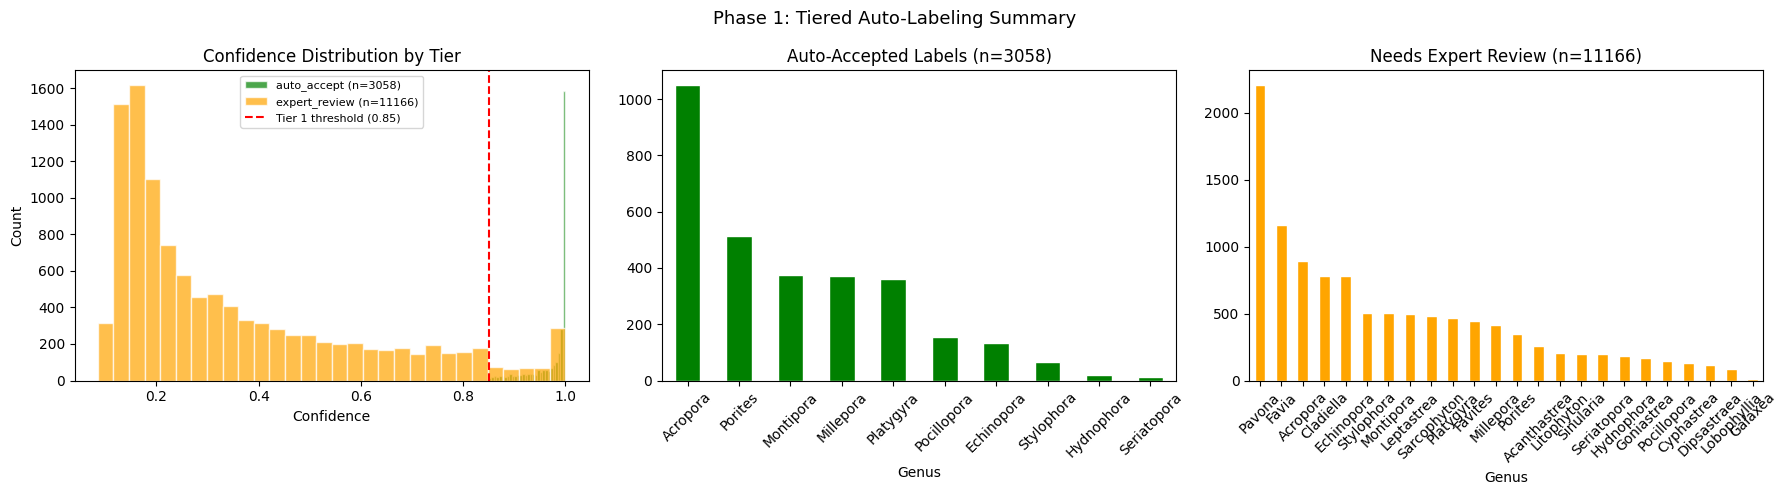

In [11]:
if PHASE == 1:
    df = pd.read_csv(os.path.join(v2_dir, 'v2_tiered_labels.csv'))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Confidence histogram by tier
    for tier, color in [('auto_accept', 'green'), ('expert_review', 'orange')]:
        subset = df[df['tier'] == tier]
        axes[0].hist(subset['confidence'], bins=30, alpha=0.7, color=color,
                     label=f'{tier} (n={len(subset)})', edgecolor='white')
    axes[0].axvline(TIER1_CONFIDENCE, color='red', linestyle='--', label=f'Tier 1 threshold ({TIER1_CONFIDENCE})')
    axes[0].set_xlabel('Confidence')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Confidence Distribution by Tier')
    axes[0].legend(fontsize=8)

    # 2. Auto-accepted genus distribution
    auto = df[df['tier'] == 'auto_accept']
    auto['predicted_genus'].value_counts().plot(kind='bar', ax=axes[1], color='green', edgecolor='white')
    axes[1].set_title(f'Auto-Accepted Labels (n={len(auto)})')
    axes[1].set_xlabel('Genus')
    axes[1].tick_params(axis='x', rotation=45)

    # 3. Expert review genus distribution
    review = df[df['tier'] == 'expert_review']
    review['predicted_genus'].value_counts().plot(kind='bar', ax=axes[2], color='orange', edgecolor='white')
    axes[2].set_title(f'Needs Expert Review (n={len(review)})')
    axes[2].set_xlabel('Genus')
    axes[2].tick_params(axis='x', rotation=45)

    plt.suptitle('Phase 1: Tiered Auto-Labeling Summary', fontsize=13)
    plt.tight_layout()
    plt.savefig(os.path.join(v2_dir, 'phase1_summary.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Skipping Phase 1 visualization")

## Phase 2: Train Supervised Classifier

**After Assaf returns the completed review CSV:**
1. Load auto-accepted labels (Tier 1) + expert corrections (Tier 2)
2. Train a LogisticRegression on BioCLIP-FT embeddings (512-dim)
3. Re-classify ALL corals with the trained model
4. Evaluate against ground truth

In [ ]:
if PHASE == 2:
    # ── LOAD TIERED LABELS ──
    df = pd.read_csv(os.path.join(v2_dir, 'v2_tiered_labels.csv'))

    # ── LOAD EMBEDDINGS ──
    emb_data = np.load(os.path.join(v2_dir, 'v2_embeddings.npz'), allow_pickle=True)
    all_embeddings = emb_data['embeddings']
    all_coral_ids  = emb_data['coral_ids']
    print(f"Loaded embeddings: {all_embeddings.shape}")

    # Build coral_id → embedding index mapping
    id_to_idx = {cid: i for i, cid in enumerate(all_coral_ids)}

    # ── LOAD EXPERT CORRECTIONS ──
    expert_path = os.path.join(v2_dir, 'expert_review_completed.csv')
    if not os.path.exists(expert_path):
        print(f"ERROR: Expert review file not found at {expert_path}")
        print("Please save Assaf's completed CSV there and re-run.")
        raise FileNotFoundError(expert_path)

    df_expert = pd.read_csv(expert_path)

    # Apply expert corrections
    n_corrected = 0
    n_confirmed = 0
    n_unknown   = 0
    expert_labels = {}

    for _, row in df_expert.iterrows():
        label = str(row.get('expert_label', '')).strip()
        if label == '' or label == 'nan':
            # Expert didn't fill in — keep model prediction
            expert_labels[row['coral_id']] = row['predicted_genus']
            n_confirmed += 1
        elif label == '?':
            # Expert can't identify — skip this coral
            expert_labels[row['coral_id']] = None
            n_unknown += 1
        else:
            # Expert provided correction
            expert_labels[row['coral_id']] = label
            if label != row['predicted_genus']:
                n_corrected += 1
            else:
                n_confirmed += 1

    # Merge expert labels into main dataframe
    for idx, row in df.iterrows():
        if row['tier'] == 'auto_accept':
            df.at[idx, 'final_label'] = row['predicted_genus']
        elif row['coral_id'] in expert_labels:
            df.at[idx, 'final_label'] = expert_labels[row['coral_id']]

    # Drop corals marked as '?' by expert
    df_labeled = df[df['final_label'].notna() & (df['final_label'] != 'None')].copy()

    print(f"\nExpert review results:")
    print(f"  Corrected:  {n_corrected}")
    print(f"  Confirmed:  {n_confirmed}")
    print(f"  Unknown (?): {n_unknown}")
    print(f"\nTotal labeled corals: {len(df_labeled)}")
    print(f"  Auto-accepted: {(df_labeled['tier'] == 'auto_accept').sum()}")
    print(f"  Expert-reviewed: {(df_labeled['tier'] == 'expert_review').sum()}")
    print(f"\nFinal label distribution:")
    print(df_labeled['final_label'].value_counts().to_string())

    df_labeled.to_csv(os.path.join(v2_dir, 'v2_final_labeled.csv'), index=False)
    print(f"\nSaved to v2_final_labeled.csv")
else:
    print("Skipping (Phase 1 — run Phase 2 after expert review)")

In [ ]:
if PHASE == 2:
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import LabelEncoder
    from sklearn.model_selection import cross_val_score, StratifiedKFold
    from sklearn.metrics import classification_report, confusion_matrix
    import pickle

    df_labeled = pd.read_csv(os.path.join(v2_dir, 'v2_final_labeled.csv'))
    emb_data = np.load(os.path.join(v2_dir, 'v2_embeddings.npz'), allow_pickle=True)
    all_embeddings = emb_data['embeddings']
    all_coral_ids  = list(emb_data['coral_ids'])

    # Build training set: embeddings + labels for all labeled corals
    id_to_idx = {cid: i for i, cid in enumerate(all_coral_ids)}

    X_train = []
    y_train = []
    for _, row in df_labeled.iterrows():
        cid = row['coral_id']
        if cid in id_to_idx:
            X_train.append(all_embeddings[id_to_idx[cid]])
            y_train.append(row['final_label'])

    X_train = np.array(X_train)
    y_train = np.array(y_train)

    # Filter out classes with too few samples (need at least 3 for cross-val)
    from collections import Counter
    class_counts = Counter(y_train)
    valid_classes = {c for c, n in class_counts.items() if n >= 3}
    mask = np.array([y in valid_classes for y in y_train])
    X_train = X_train[mask]
    y_train = y_train[mask]

    print(f"Training set: {X_train.shape[0]} samples, {len(valid_classes)} classes")
    print(f"Dropped classes with < 3 samples: {set(class_counts.keys()) - valid_classes}")

    # ── ENCODE LABELS ──
    le = LabelEncoder()
    y_encoded = le.fit_transform(y_train)

    # ── CROSS-VALIDATION ──
    n_splits = min(5, min(class_counts[c] for c in valid_classes))
    if n_splits >= 2:
        cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
        scores = cross_val_score(
            LogisticRegression(max_iter=2000, C=1.0, class_weight='balanced'),
            X_train, y_encoded, cv=cv, scoring='accuracy'
        )
        print(f"\nCross-validation ({n_splits}-fold): {scores.mean():.3f} +/- {scores.std():.3f}")
    else:
        print("\nNot enough samples per class for cross-validation")

    # ── TRAIN FINAL MODEL ──
    clf = LogisticRegression(max_iter=2000, C=1.0, class_weight='balanced')
    clf.fit(X_train, y_encoded)

    # In-sample accuracy (sanity check)
    train_acc = clf.score(X_train, y_encoded)
    print(f"Training accuracy: {train_acc:.3f}")

    # ── SAVE MODEL ──
    model_path = os.path.join(v2_dir, 'classifier_logreg.pkl')
    with open(model_path, 'wb') as f:
        pickle.dump({'model': clf, 'label_encoder': le, 'classes': list(le.classes_)}, f)
    print(f"\nClassifier saved to {model_path}")
    print(f"Classes: {list(le.classes_)}")
else:
    print("Skipping classifier training (Phase 1)")

In [ ]:
if PHASE == 2:
    import pickle

    # Load classifier
    with open(os.path.join(v2_dir, 'classifier_logreg.pkl'), 'rb') as f:
        clf_data = pickle.load(f)
    clf = clf_data['model']
    le  = clf_data['label_encoder']

    # Load all embeddings
    emb_data = np.load(os.path.join(v2_dir, 'v2_embeddings.npz'), allow_pickle=True)
    all_embeddings = emb_data['embeddings']
    all_coral_ids  = list(emb_data['coral_ids'])
    all_img_names  = list(emb_data['image_names'])

    # Predict on ALL corals
    y_pred_encoded = clf.predict(all_embeddings)
    y_pred_proba   = clf.predict_proba(all_embeddings)
    y_pred_labels  = le.inverse_transform(y_pred_encoded)
    y_pred_conf    = y_pred_proba.max(axis=1)

    # Build final predictions dataframe
    df_all = pd.read_csv(os.path.join(v2_dir, 'v2_weak_labels_expanded.csv'))

    # Map coral_id to classifier prediction
    clf_pred_map = {cid: (label, conf) for cid, label, conf
                    in zip(all_coral_ids, y_pred_labels, y_pred_conf)}

    df_all['clf_predicted_genus'] = df_all['coral_id'].map(
        lambda x: clf_pred_map.get(x, (None, None))[0]
    )
    df_all['clf_confidence'] = df_all['coral_id'].map(
        lambda x: clf_pred_map.get(x, (None, None))[1]
    )

    # Final label: use classifier prediction for everything
    # but prefer expert label where available
    df_labeled = pd.read_csv(os.path.join(v2_dir, 'v2_final_labeled.csv'))
    expert_map = dict(zip(df_labeled['coral_id'], df_labeled['final_label']))

    df_all['final_genus'] = df_all['coral_id'].map(
        lambda x: expert_map.get(x, clf_pred_map.get(x, (None,))[0])
    )

    output_path = os.path.join(v2_dir, 'v2_all_corals_final.csv')
    df_all.to_csv(output_path, index=False)

    print(f"Applied classifier to {len(df_all)} corals")
    print(f"\nClassifier prediction distribution:")
    print(df_all['clf_predicted_genus'].value_counts().to_string())
    print(f"\nMean classifier confidence: {df_all['clf_confidence'].mean():.3f}")
    print(f"\nFinal genus distribution (expert + classifier):")
    print(df_all['final_genus'].value_counts().to_string())
    print(f"\nSaved to {output_path}")
else:
    print("Skipping re-classification (Phase 1)")

In [ ]:
if PHASE == 2:
    # ── GROUND TRUTH ──
    df_gt = pd.read_csv(gt_path)
    df_gt = df_gt.rename(columns={"Observation": "genus", "#": "count"})

    df_all = pd.read_csv(os.path.join(v2_dir, 'v2_all_corals_final.csv'))

    # Compare: zero-shot vs classifier vs ground truth
    all_genera_in_gt = df_gt['genus'].tolist()
    all_genera_pred  = list(set(
        df_all['predicted_genus'].unique().tolist() +
        df_all['clf_predicted_genus'].dropna().unique().tolist()
    ))

    # Intersect with ground truth genera
    compare_genera = sorted(set(all_genera_in_gt) & set(all_genera_pred))

    gt_sub = df_gt[df_gt['genus'].isin(compare_genera)].set_index('genus')
    gt_total = gt_sub['count'].sum()
    gt_prop = gt_sub['count'] / gt_total

    # Zero-shot proportions
    zs_counts = df_all['predicted_genus'].value_counts().reindex(compare_genera, fill_value=0)
    zs_prop = zs_counts / zs_counts.sum()

    # Classifier proportions
    clf_counts = df_all['clf_predicted_genus'].value_counts().reindex(compare_genera, fill_value=0)
    clf_prop = clf_counts / clf_counts.sum()

    # Final proportions
    final_counts = df_all['final_genus'].value_counts().reindex(compare_genera, fill_value=0)
    final_prop = final_counts / final_counts.sum()

    # ── GROUPED BAR CHART ──
    x = np.arange(len(compare_genera))
    width = 0.2

    fig, ax = plt.subplots(figsize=(18, 6))
    ax.bar(x - 1.5*width, gt_prop.reindex(compare_genera, fill_value=0).values,
           width, label='Ground Truth', color='black')
    ax.bar(x - 0.5*width, zs_prop.values,
           width, label='Zero-Shot (v2 expanded)', color='steelblue')
    ax.bar(x + 0.5*width, clf_prop.values,
           width, label='Classifier (LogReg)', color='coral')
    ax.bar(x + 1.5*width, final_prop.values,
           width, label='Final (expert + clf)', color='green')

    ax.set_xticks(x)
    ax.set_xticklabels(compare_genera, rotation=60, ha='right')
    ax.set_ylabel('Proportion')
    ax.set_title('Genus Distribution: Ground Truth vs Zero-Shot vs Classifier vs Final')
    ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(v2_dir, 'phase2_evaluation.png'), dpi=150, bbox_inches='tight')
    plt.show()

    # ── RATIO TABLE ──
    n_zs  = zs_counts.sum()
    n_clf = clf_counts.sum()
    n_fin = final_counts.sum()

    df_ratio = pd.DataFrame(index=compare_genera)
    df_ratio['gt_count'] = gt_sub['count'].reindex(compare_genera, fill_value=0)
    df_ratio['zs_pred']  = zs_counts.values
    df_ratio['zs_ratio'] = (zs_counts / (gt_prop.reindex(compare_genera, fill_value=0.001) * n_zs)).round(2).values
    df_ratio['clf_pred']  = clf_counts.values
    df_ratio['clf_ratio'] = (clf_counts / (gt_prop.reindex(compare_genera, fill_value=0.001) * n_clf)).round(2).values
    df_ratio['final_pred']  = final_counts.values
    df_ratio['final_ratio'] = (final_counts / (gt_prop.reindex(compare_genera, fill_value=0.001) * n_fin)).round(2).values

    print("\nOver/under-prediction ratio (1.0 = perfect match):")
    print(df_ratio.to_string())
else:
    print("Skipping evaluation (Phase 1)")

In [ ]:
if PHASE == 2:
    import seaborn as sns

    # Compare zero-shot vs classifier on the LABELED subset
    df_labeled = pd.read_csv(os.path.join(v2_dir, 'v2_final_labeled.csv'))
    emb_data = np.load(os.path.join(v2_dir, 'v2_embeddings.npz'), allow_pickle=True)
    all_embeddings = emb_data['embeddings']
    all_coral_ids  = list(emb_data['coral_ids'])

    import pickle
    with open(os.path.join(v2_dir, 'classifier_logreg.pkl'), 'rb') as f:
        clf_data = pickle.load(f)
    clf = clf_data['model']
    le  = clf_data['label_encoder']

    id_to_idx = {cid: i for i, cid in enumerate(all_coral_ids)}

    y_true = []
    y_zs   = []
    y_clf  = []

    for _, row in df_labeled.iterrows():
        cid = row['coral_id']
        if cid not in id_to_idx:
            continue
        true_label = row['final_label']
        if true_label not in le.classes_:
            continue
        y_true.append(true_label)
        y_zs.append(row['predicted_genus'])
        emb = all_embeddings[id_to_idx[cid]].reshape(1, -1)
        y_clf.append(le.inverse_transform(clf.predict(emb))[0])

    # Accuracy comparison
    zs_acc  = np.mean([t == z for t, z in zip(y_true, y_zs)])
    clf_acc = np.mean([t == c for t, c in zip(y_true, y_clf)])

    print(f"Zero-shot accuracy on labeled set: {zs_acc:.3f}")
    print(f"Classifier accuracy on labeled set: {clf_acc:.3f}")
    print(f"Improvement: {clf_acc - zs_acc:+.3f}")

    # Confusion matrix for classifier
    labels = sorted(set(y_true))
    cm = confusion_matrix(y_true, y_clf, labels=labels)

    fig, ax = plt.subplots(figsize=(12, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel('Predicted (Classifier)')
    ax.set_ylabel('True (Expert)')
    ax.set_title('Confusion Matrix — Trained Classifier')
    plt.tight_layout()
    plt.savefig(os.path.join(v2_dir, 'confusion_matrix_classifier.png'), dpi=150, bbox_inches='tight')
    plt.show()

    # Per-class report
    print("\nClassification Report (Classifier):")
    print(classification_report(y_true, y_clf, labels=labels, zero_division=0))
else:
    print("Skipping confusion matrix (Phase 1)")

## Visualization
Show sample predictions from the final classifier alongside the zero-shot predictions.

In [ ]:
if PHASE == 2:
    import pickle

    df_all = pd.read_csv(os.path.join(v2_dir, 'v2_all_corals_final.csv'))

    N_SAMPLES = 40
    COLS = 4

    sample = df_all.sample(n=min(N_SAMPLES, len(df_all)), random_state=42).reset_index(drop=True)

    rows = (len(sample) + COLS - 1) // COLS
    fig, axes = plt.subplots(rows, COLS, figsize=(COLS * 4, rows * 4))
    axes = axes.flatten()

    for i, row in sample.iterrows():
        ax = axes[i]
        img_path = os.path.join(data_path, row['image_name'])
        image = cv2.imread(img_path)
        if image is None:
            ax.axis('off')
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (2560, 1920))

        bbox = eval(row['bbox']) if isinstance(row['bbox'], str) else row['bbox']

        img_stem = os.path.splitext(row['image_name'])[0]
        json_path = os.path.join(json_dir, img_stem + '.json')
        rle = None
        if os.path.exists(json_path):
            with open(json_path, 'r') as f:
                jdata = json.load(f)
            for anno in jdata['annotations']:
                if anno['id'] == row['coral_id']:
                    rle = anno['segmentation']
                    break

        crop = get_masked_crop(image, bbox, rle,
                               padding_pct=MASK_PADDING_PCT,
                               background=MASK_BACKGROUND) if rle else get_crop(image, bbox)
        if crop is None:
            crop = get_crop(image, bbox)
        if crop is None:
            ax.axis('off')
            continue

        ax.imshow(crop)
        ax.axis('off')

        zs_genus = row['predicted_genus']
        clf_genus = row.get('clf_predicted_genus', zs_genus)
        clf_conf  = row.get('clf_confidence', row['confidence'])
        final     = row.get('final_genus', clf_genus)

        color = 'green' if clf_conf >= 0.7 else 'orange' if clf_conf >= 0.4 else 'red'
        title = f"Final: {final}\nZS: {zs_genus} | CLF: {clf_genus}\nconf: {clf_conf:.2f}"
        ax.set_title(title, fontsize=8, color=color, pad=4)

    for j in range(len(sample), len(axes)):
        axes[j].axis('off')

    plt.suptitle('Final Predictions — sample of 40 corals\n'
                 '(Final = expert label where available, else classifier)',
                 fontsize=12, y=1.01)
    plt.tight_layout()
    plt.savefig(os.path.join(v2_dir, 'v2_sample_predictions.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Skipping visualization (Phase 1)")

In [ ]:
if PHASE == 2:
    df_all = pd.read_csv(os.path.join(v2_dir, 'v2_all_corals_final.csv'))

    # Clean export: just the columns needed for downstream use
    df_export = df_all[['image_name', 'coral_id', 'bbox', 'area',
                        'final_genus', 'clf_confidence']].copy()
    df_export = df_export.rename(columns={
        'final_genus': 'genus',
        'clf_confidence': 'confidence'
    })
    df_export = df_export.dropna(subset=['genus'])

    export_path = os.path.join(v2_dir, 'coral_genus_labels_final.csv')
    df_export.to_csv(export_path, index=False)

    print(f"Final labeled dataset: {len(df_export)} corals")
    print(f"Saved to {export_path}")
    print(f"\nGenus distribution:")
    print(df_export['genus'].value_counts().to_string())
    print(f"\nMean confidence: {df_export['confidence'].mean():.3f}")
    print(f"\nReady for downstream tasks (clustering, training, analysis)")
else:
    print("Skipping final export (Phase 1)")